In [1]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

print("Model trained successfully")

Model trained successfully


In [2]:
import joblib

joblib.dump(model, "model.joblib")
print("Model saved successfully")

Model saved successfully


In [3]:
import joblib

loaded_model = joblib.load("model.joblib")
print("Model loaded successfully")

Model loaded successfully


In [4]:
prediction = loaded_model.predict(X_test[:1])
print("Prediction:", data.target_names[prediction[0]])

Prediction: benign


In [5]:
from sklearn.metrics import accuracy_score

predictions = loaded_model.predict(X_test)
accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", round(accuracy * 100, 2), "%")

Accuracy: 96.49 %


In [6]:
import tensorflow as tf
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)

deep_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(X_train.shape[1],)),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1, activation="sigmoid")
])

deep_model.compile(optimizer="adam",
                   loss="binary_crossentropy",
                   metrics=["accuracy"])

deep_model.fit(X_train_scaled, y_train, epochs=5, verbose=0)
deep_model.save("deep_model.keras")

print("Deep learning model saved")

Deep learning model saved


In [7]:
import tensorflow as tf
import joblib

joblib.dump(scaler, "scaler.joblib")
loaded_deep_model = tf.keras.models.load_model("deep_model.keras")
loaded_scaler = joblib.load("scaler.joblib")

sample = loaded_scaler.transform(X_test[:1])
probability = loaded_deep_model.predict(sample, verbose=0)

print("Predicted probability:", probability[0][0])

Predicted probability: 0.59421545


In [8]:
from sklearn.linear_model import LogisticRegression

lr = LogisticRegression(max_iter=2000)
lr.fit(X_train, y_train)

print("Logistic Regression trained")

Logistic Regression trained


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [9]:
from sklearn.tree import DecisionTreeClassifier

dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

print("Decision Tree trained")

Decision Tree trained


In [10]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("Random Forest trained")

Random Forest trained


In [11]:
from sklearn.metrics import accuracy_score

models = {
    "Logistic Regression": lr,
    "Decision Tree": dt,
    "Random Forest": rf
}

for name, model in models.items():
    pred = model.predict(X_test)
    print(name, "Accuracy:",
          round(accuracy_score(y_test, pred) * 100, 2), "%")

Logistic Regression Accuracy: 95.61 %
Decision Tree Accuracy: 94.74 %
Random Forest Accuracy: 96.49 %


In [12]:
from sklearn.metrics import precision_score, recall_score, f1_score

pred = rf.predict(X_test)

print("Precision:", precision_score(y_test, pred))
print("Recall:", recall_score(y_test, pred))
print("F1 Score:", f1_score(y_test, pred))

Precision: 0.958904109589041
Recall: 0.9859154929577465
F1 Score: 0.9722222222222222


In [13]:
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    {"n_estimators": [50, 100],
     "max_depth": [5, 10, None]},
    cv=3,
    scoring="accuracy"
)

grid.fit(X_train, y_train)

print("Best Parameters:", grid.best_params_)
print("Best CV Accuracy:", grid.best_score_)

Best Parameters: {'max_depth': 10, 'n_estimators': 50}
Best CV Accuracy: 0.956009643313582


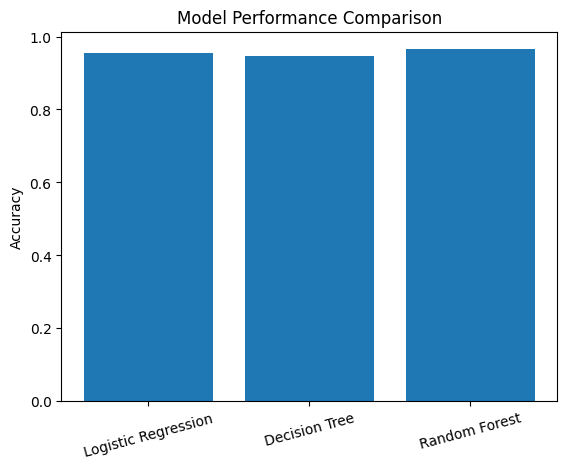

In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score

names = ["Logistic Regression", "Decision Tree", "Random Forest"]
scores = [
    accuracy_score(y_test, lr.predict(X_test)),
    accuracy_score(y_test, dt.predict(X_test)),
    accuracy_score(y_test, rf.predict(X_test))
]

plt.bar(names, scores)
plt.ylabel("Accuracy")
plt.title("Model Performance Comparison")
plt.xticks(rotation=15)
plt.show()

In [15]:
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Dataset prepared")

Dataset prepared


In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

lr = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000)
)

lr.fit(X_train, y_train)
print("Logistic Regression completed")

Logistic Regression completed


In [17]:
from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

print("Random Forest completed")

Random Forest completed


In [18]:
from sklearn.ensemble import GradientBoostingClassifier

gb = GradientBoostingClassifier(random_state=42)
gb.fit(X_train, y_train)

print("Gradient Boosting completed")

Gradient Boosting completed


In [19]:
from sklearn.ensemble import VotingClassifier

ensemble = VotingClassifier(
    estimators=[
        ("lr", lr),
        ("rf", rf),
        ("gb", gb)
    ],
    voting="soft"
)

ensemble.fit(X_train, y_train)
print("Ensemble model trained")

Ensemble model trained


In [20]:
from sklearn.metrics import accuracy_score, confusion_matrix

pred = ensemble.predict(X_test)

print("Accuracy:", accuracy_score(y_test, pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, pred))

Accuracy: 0.9649122807017544
Confusion Matrix:
 [[40  3]
 [ 1 70]]


In [21]:
import joblib

joblib.dump(ensemble, "ensemble_model.joblib")

saved_model = joblib.load("ensemble_model.joblib")
result = saved_model.predict(X_test[:1])

print("Prediction:", data.target_names[result[0]])

Prediction: benign
